# Wczytanie danych

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Wczytanie obu arkuszy
df1 = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2009-2010')
df2 = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2010-2011')
df = pd.concat([df1, df2], ignore_index=True)

print(f"Rozmiar datasetu: {df.shape}")
print(f"\nKolumny: {df.columns.tolist()}")
print(f"\nTypy danych:\n{df.dtypes}")

Rozmiar datasetu: (1067371, 8)

Kolumny: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Typy danych:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object


# Braki i podstawowe statystyki

In [2]:
print("=== BRAKUJĄCE WARTOŚCI ===")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({'count': missing, 'pct': missing_pct}))

print("\n=== PODSTAWOWE STATYSTYKI ===")
print(df[['Quantity', 'Price']].describe())

=== BRAKUJĄCE WARTOŚCI ===


              count    pct
Invoice           0   0.00
StockCode         0   0.00
Description    4382   0.41
Quantity          0   0.00
InvoiceDate       0   0.00
Price             0   0.00
Customer ID  243007  22.77
Country           0   0.00

=== PODSTAWOWE STATYSTYKI ===
           Quantity         Price
count  1.067371e+06  1.067371e+06
mean   9.938898e+00  4.649388e+00
std    1.727058e+02  1.235531e+02
min   -8.099500e+04 -5.359436e+04
25%    1.000000e+00  1.250000e+00
50%    3.000000e+00  2.100000e+00
75%    1.000000e+01  4.150000e+00
max    8.099500e+04  3.897000e+04


# Szybki podgląd

In [3]:
print("=== PIERWSZYCH 5 WIERSZY ===")
display(df.head())

print(f"\n=== ZAKRES DAT ===")
print(f"Od: {df['InvoiceDate'].min()}")
print(f"Do: {df['InvoiceDate'].max()}")

print(f"\n=== UNIKALNE WARTOŚCI ===")
print(f"Klientów:  {df['Customer ID'].nunique()}")
print(f"Produktów: {df['StockCode'].nunique()}")
print(f"Krajów:    {df['Country'].nunique()}")
print(f"Faktur:    {df['Invoice'].nunique()}")

=== PIERWSZYCH 5 WIERSZY ===


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



=== ZAKRES DAT ===
Od: 2009-12-01 07:45:00
Do: 2011-12-09 12:50:00

=== UNIKALNE WARTOŚCI ===


Klientów:  5942
Produktów: 5305
Krajów:    43


Faktur:    53628


# Czyszczenie danych

In [4]:
print("=== PRZED CZYSZCZENIEM ===")
print(f"Wierszy: {len(df)}")

# 1. Usunięcie wierszy bez Customer ID
df_clean = df.dropna(subset=['Customer ID']).copy()
df_clean['Customer ID'] = df_clean['Customer ID'].astype(int)
print(f"\nPo usunięciu braków Customer ID: {len(df_clean)} ({len(df_clean)/len(df)*100:.1f}%)")

# 1.5. Usunięcie w pełni zbilansowanych transakcji: zakup w całości
#      zwrócony tego samego dnia (ten sam klient, produkt i ilość).
#      Przykłady motywujące: klient 16446 (faktura 581483, 80995 szt.
#      PAPER CRAFT, LITTLE BIRDIE) i klient 12346 (faktura 541431,
#      74215 szt. MEDIUM CERAMIC TOP STORAGE JAR) - oba kupione
#      i zwrócone tego samego dnia, netto zero, a bez tego kroku
#      rekord zakupu sztucznie zawyżałby Monetary tych klientów.
df_clean['Day'] = df_clean['InvoiceDate'].dt.date
is_return = df_clean['Invoice'].astype(str).str.startswith('C')
returns_tmp = df_clean[is_return]
purchases_tmp = df_clean[~is_return]

purch_idx_by_key = {}
for idx, r_cid, r_sc, r_qty, r_day in purchases_tmp[['Customer ID', 'StockCode', 'Quantity', 'Day']].itertuples():
    key = (r_cid, r_sc, r_qty, r_day)
    purch_idx_by_key.setdefault(key, []).append(idx)

matched_purchase_idx = set()
for idx, r_cid, r_sc, r_qty, r_day in returns_tmp[['Customer ID', 'StockCode', 'Quantity', 'Day']].itertuples():
    key = (r_cid, r_sc, -r_qty, r_day)
    for cand in purch_idx_by_key.get(key, []):
        if cand not in matched_purchase_idx:
            matched_purchase_idx.add(cand)
            break

print(f"W pełni zbilansowane transakcje (ten sam dzień, dopasowane pary): {len(matched_purchase_idx)}")

df_clean = df_clean.drop(index=list(matched_purchase_idx))
df_clean = df_clean.drop(columns=['Day'])
print(f"Po usunięciu zbilansowanych transakcji: {len(df_clean)}")

# Weryfikacja: faktury flagowane w pracy (16446, 12346) znikają
for invoice_check in ['581483', '541431']:
    still_present = (df_clean['Invoice'].astype(str) == invoice_check).sum()
    print(f"  Faktura {invoice_check} obecna po usunięciu: {still_present} rekordów (oczekiwano: 0)")

# 2. Usunięcie zwrotów (Invoice zaczyna się od 'C')
mask_returns = df_clean['Invoice'].astype(str).str.startswith('C')
print(f"Zwroty: {mask_returns.sum()} wierszy")
df_clean = df_clean[~mask_returns]

# 3. Usunięcie ujemnych i zerowych cen oraz ilości
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['Price'] > 0)]
print(f"Po usunięciu ujemnych Quantity/Price: {len(df_clean)}")

# 4. Usunięcie anomalnych StockCode (np. 'POST', 'D', 'M' - opłaty, rabaty)
anomaly_codes = ['POST', 'D', 'M', 'BANK CHARGES', 'PADS', 'DOT']
df_clean = df_clean[~df_clean['StockCode'].isin(anomaly_codes)]

# 5. Kolumna TotalPrice
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['Price']

print(f"\n=== PO CZYSZCZENIU ===")
print(f"Wierszy: {len(df_clean)}")
print(f"Klientów: {df_clean['Customer ID'].nunique()}")
print(f"Utracono: {len(df)-len(df_clean)} wierszy ({(len(df)-len(df_clean))/len(df)*100:.1f}%)")

=== PRZED CZYSZCZENIEM ===
Wierszy: 1067371



Po usunięciu braków Customer ID: 824364 (77.2%)


W pełni zbilansowane transakcje (ten sam dzień, dopasowane pary): 1763
Po usunięciu zbilansowanych transakcji: 822601


  Faktura 581483 obecna po usunięciu: 0 rekordów (oczekiwano: 0)


  Faktura 541431 obecna po usunięciu: 0 rekordów (oczekiwano: 0)


Zwroty: 18744 wierszy


Po usunięciu ujemnych Quantity/Price: 803786

=== PO CZYSZCZENIU ===
Wierszy: 801291
Klientów: 5859
Utracono: 266080 wierszy (24.9%)


# Rozkłady i analiza czasowa

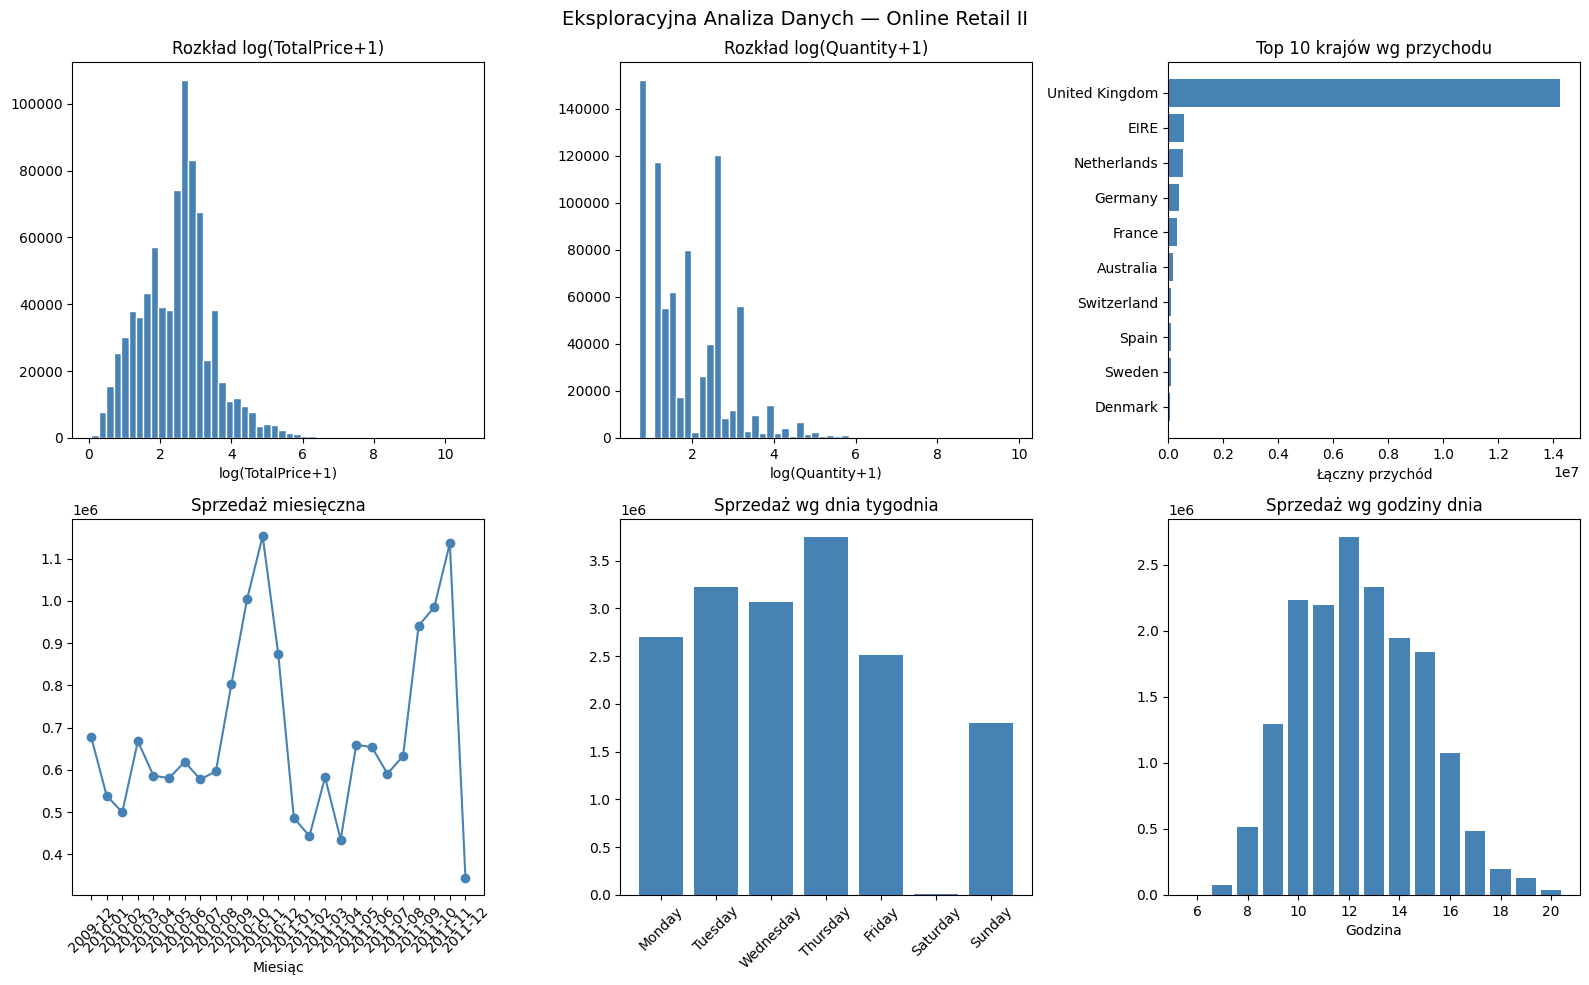

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Eksploracyjna Analiza Danych — Online Retail II', fontsize=14)

# 1. Rozkład TotalPrice (log)
axes[0,0].hist(np.log1p(df_clean['TotalPrice']), bins=50, color='steelblue', edgecolor='white')
axes[0,0].set_title('Rozkład log(TotalPrice+1)')
axes[0,0].set_xlabel('log(TotalPrice+1)')

# 2. Rozkład Quantity (log)
axes[0,1].hist(np.log1p(df_clean['Quantity']), bins=50, color='steelblue', edgecolor='white')
axes[0,1].set_title('Rozkład log(Quantity+1)')
axes[0,1].set_xlabel('log(Quantity+1)')

# 3. Top 10 krajów
top_countries = df_clean.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(10)
axes[0,2].barh(top_countries.index[::-1], top_countries.values[::-1], color='steelblue')
axes[0,2].set_title('Top 10 krajów wg przychodu')
axes[0,2].set_xlabel('Łączny przychód')

# 4. Sprzedaż miesięczna
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
monthly = df_clean.groupby('YearMonth')['TotalPrice'].sum()
axes[1,0].plot(monthly.index.astype(str), monthly.values, marker='o', color='steelblue')
axes[1,0].set_title('Sprzedaż miesięczna')
axes[1,0].set_xlabel('Miesiąc')
axes[1,0].tick_params(axis='x', rotation=45)

# 5. Sprzedaż wg dnia tygodnia
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
daily = df_clean.groupby('DayOfWeek')['TotalPrice'].sum().reindex(day_order)
axes[1,1].bar(daily.index, daily.values, color='steelblue')
axes[1,1].set_title('Sprzedaż wg dnia tygodnia')
axes[1,1].tick_params(axis='x', rotation=45)

# 6. Sprzedaż wg godziny
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour
hourly = df_clean.groupby('Hour')['TotalPrice'].sum()
axes[1,2].bar(hourly.index, hourly.values, color='steelblue')
axes[1,2].set_title('Sprzedaż wg godziny dnia')
axes[1,2].set_xlabel('Godzina')

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

# Statystyki opisowe po czyszczeniu

In [6]:
print("=== STATYSTYKI PO CZYSZCZENIU ===")
print(df_clean[['Quantity', 'Price', 'TotalPrice']].describe().round(2))

print("\n=== KONCENTRACJA SPRZEDAŻY (zasada Pareto) ===")
customer_revenue = df_clean.groupby('Customer ID')['TotalPrice'].sum().sort_values(ascending=False)
top20_pct = int(len(customer_revenue) * 0.2)
top20_revenue = customer_revenue.head(top20_pct).sum() / customer_revenue.sum() * 100
print(f"Top 20% klientów generuje {top20_revenue:.1f}% przychodu")

print("\n=== UDZIAŁ UK W SPRZEDAŻY ===")
uk_revenue = df_clean[df_clean['Country']=='United Kingdom']['TotalPrice'].sum()
total_revenue = df_clean['TotalPrice'].sum()
print(f"UK: {uk_revenue/total_revenue*100:.1f}% całkowitego przychodu")

=== STATYSTYKI PO CZYSZCZENIU ===
        Quantity      Price  TotalPrice
count  801291.00  801291.00   801291.00
mean       13.05       2.95       21.30
std        75.03       4.46       81.12
min         1.00       0.03        0.06
25%         2.00       1.25        4.95
50%         5.00       1.95       11.80
75%        12.00       3.75       19.50
max     19152.00     649.50    38970.00

=== KONCENTRACJA SPRZEDAŻY (zasada Pareto) ===
Top 20% klientów generuje 76.8% przychodu

=== UDZIAŁ UK W SPRZEDAŻY ===


UK: 83.6% całkowitego przychodu


# Analiza outlierów

In [7]:
print("=== ANALIZA OUTLINERÓW ===")

# Ile wierszy to "normalna" sprzedaż vs duże zamówienia?
q99_qty = df_clean['Quantity'].quantile(0.99)
q99_price = df_clean['TotalPrice'].quantile(0.99)

print(f"99. percentyl Quantity:   {q99_qty:.0f}")
print(f"99. percentyl TotalPrice: {q99_price:.2f}")

pct_above_q99_qty = (df_clean['Quantity'] > q99_qty).sum() / len(df_clean) * 100
pct_above_q99_price = (df_clean['TotalPrice'] > q99_price).sum() / len(df_clean) * 100

print(f"\nWierszy powyżej 99p Quantity:   {pct_above_q99_qty:.2f}%")
print(f"Wierszy powyżej 99p TotalPrice: {pct_above_q99_price:.2f}%")

# Klienci z ekstremalnie wysokim przychodem
customer_revenue = df_clean.groupby('Customer ID')['TotalPrice'].sum().sort_values(ascending=False)
print(f"\n=== TOP 10 KLIENTÓW WG PRZYCHODU ===")
print(customer_revenue.head(10).round(2))

# Percentyle rozkładu przychodów klientów
print(f"\n=== ROZKŁAD PRZYCHODÓW KLIENTÓW ===")
print(customer_revenue.describe(percentiles=[.25,.5,.75,.90,.95,.99]).round(2))

=== ANALIZA OUTLINERÓW ===
99. percentyl Quantity:   128
99. percentyl TotalPrice: 192.00

Wierszy powyżej 99p Quantity:   0.98%
Wierszy powyżej 99p TotalPrice: 1.00%

=== TOP 10 KLIENTÓW WG PRZYCHODU ===
Customer ID
18102    607539.25
14646    526751.52
14156    304727.96
14911    276402.34
17450    240648.01
13694    194595.01
17511    173097.55
16684    144129.77
12415    143874.72
15061    137664.43
Name: TotalPrice, dtype: float64

=== ROZKŁAD PRZYCHODÓW KLIENTÓW ===
count      5859.00
mean       2912.83
std       14310.41
min           2.90
25%         343.56
50%         877.70
75%        2266.77
90%        5434.01
95%        9316.85
99%       27742.41
max      607539.25
Name: TotalPrice, dtype: float64


# Zapis czystego datasetu

In [8]:
df_clean.drop(columns=['YearMonth', 'DayOfWeek', 'Hour'], inplace=True, errors='ignore')
df_clean.to_csv('online_retail_clean.csv', index=False)
print("Zapisano: online_retail_clean.csv")
print("Następnym razem wczytaj przez: df_clean = pd.read_csv('online_retail_clean.csv', parse_dates=['InvoiceDate'])")

Zapisano: online_retail_clean.csv
Następnym razem wczytaj przez: df_clean = pd.read_csv('online_retail_clean.csv', parse_dates=['InvoiceDate'])
